## Objective

Build and evaluate five machine learning models for Telco Customer Churn Prediction using reusable preprocessing functions, complete Scikit-learn Pipelines, and 5-fold Stratified Cross-Validation.

## Models

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. XGBoost

## Evaluation Approach

- Using a stratified 80/20 train-test split.
- Applying 5-fold Stratified Cross-Validation to the training set.
- Comparing model performance using appropriate classification metrics.
- Printing a classification report for each model.
- Selecting the best-performing model using cross-validation results.
- Evaluating the selected model on the untouched test set.
- Performing hyperparameter tuning on the selected model.

In [1]:
# Importing reusable preprocessing functions

import sys
sys.path.append("..")

from src.preprocessing import (
    load_data,
    clean_data,
    engineer_features,
    prepare_features_target,
    split_data,
    identify_feature_types,
    build_preprocessor
)

print("Preprocessing functions imported successfully.")

Preprocessing functions imported successfully.


In [2]:
# Loading the dataset
df = load_data("../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Cleaning the data
df = clean_data(df)

# Engineering features
df = engineer_features(df)

# Separating features and target
X, y = prepare_features_target(df)

# Splitting into training and testing sets
X_train, X_test, y_train, y_test = split_data(X, y)

# Identifying feature types using training features
numeric_features, categorical_features = identify_feature_types(X_train)

print("Dataset shape:", df.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nNumber of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Dataset shape: (7043, 22)
X_train shape: (5634, 21)
X_test shape: (1409, 21)
y_train shape: (5634,)
y_test shape: (1409,)

Number of numeric features: 5
Number of categorical features: 16


In [3]:
# Model building imports

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [12]:
import time

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

print("Training and evaluation utilities imported successfully.")

Training and evaluation utilities imported successfully.


In [5]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [10]:
# Creating five model dictionary

from xgboost import XGBClassifier

from sklearn.utils.class_weight import compute_sample_weight

# Calculate the positive-class weight using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Number of models:", len(models))
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))



Number of models: 5
XGBoost scale_pos_weight: 2.77


In [11]:
# Building the five model pipelines

model_pipelines = {}

for name, model in models.items():
    model_pipelines[name] = Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(
                    numeric_features,
                    categorical_features
                )
            ),
            ("model", model)
        ]
    )

print("Number of model pipelines:", len(model_pipelines))

Number of model pipelines: 5


In [8]:
# Configuring cross-validation

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation:", cv)
print("Number of folds:", cv.get_n_splits())

Cross-validation: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Number of folds: 5


In [9]:
# Checking fold sizes

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    print(
        f"Fold {fold}: "
        f"Training rows = {len(train_idx)}, "
        f"Validation rows = {len(val_idx)}, "
        f"Validation churn rate = "
        f"{y_train.iloc[val_idx].mean():.2%}"
    )

Fold 1: Training rows = 4507, Validation rows = 1127, Validation churn rate = 26.53%
Fold 2: Training rows = 4507, Validation rows = 1127, Validation churn rate = 26.53%
Fold 3: Training rows = 4507, Validation rows = 1127, Validation churn rate = 26.53%
Fold 4: Training rows = 4507, Validation rows = 1127, Validation churn rate = 26.53%
Fold 5: Training rows = 4508, Validation rows = 1126, Validation churn rate = 26.55%


In [13]:
# Adding the training loop

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

cv_results = []

for model_name, pipeline in model_pipelines.items():
    print(f"\nTraining: {model_name}")

    fold_number = 0

    for train_idx, val_idx in cv.split(X_train, y_train):
        fold_number += 1

        # Split this fold's data
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Create a fresh pipeline for this fold
        fold_pipeline = clone(pipeline)

        # Handle class imbalance using fold-training labels only
        fit_params = {}

        if model_name == "Gradient Boosting":
            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )
            fit_params["model__sample_weight"] = sample_weights

        elif model_name == "XGBoost":
            negative_count = (y_fold_train == 0).sum()
            positive_count = (y_fold_train == 1).sum()

            fold_scale_pos_weight = (
                negative_count / positive_count
            )

            fold_pipeline.set_params(
                model__scale_pos_weight=fold_scale_pos_weight
            )

        # Fit and time the complete pipeline
        start_time = time.time()

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train,
            **fit_params
        )

        training_time = time.time() - start_time

        # Predict on the validation fold
        y_pred = fold_pipeline.predict(X_fold_val)
        y_proba = fold_pipeline.predict_proba(X_fold_val)[:, 1]

        # Calculate validation metrics
        cv_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Accuracy": accuracy_score(y_fold_val, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(
                y_fold_val, y_pred
            ),
            "Precision": precision_score(
                y_fold_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_fold_val, y_pred, zero_division=0
            ),
            "F1 Score": f1_score(
                y_fold_val, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_fold_val, y_proba),
            "Training Time (sec)": training_time
        })

        print(
            f"  Fold {fold_number}/5 completed "
            f"in {training_time:.2f} seconds"
        )

print("\nCross-validation training completed.")


Training: Logistic Regression
  Fold 1/5 completed in 0.41 seconds
  Fold 2/5 completed in 0.05 seconds
  Fold 3/5 completed in 0.09 seconds
  Fold 4/5 completed in 0.11 seconds
  Fold 5/5 completed in 0.10 seconds

Training: Decision Tree
  Fold 1/5 completed in 0.08 seconds
  Fold 2/5 completed in 0.06 seconds
  Fold 3/5 completed in 0.07 seconds
  Fold 4/5 completed in 0.08 seconds
  Fold 5/5 completed in 0.07 seconds

Training: Random Forest
  Fold 1/5 completed in 0.40 seconds
  Fold 2/5 completed in 0.32 seconds
  Fold 3/5 completed in 0.33 seconds
  Fold 4/5 completed in 0.32 seconds
  Fold 5/5 completed in 0.33 seconds

Training: Gradient Boosting
  Fold 1/5 completed in 0.84 seconds
  Fold 2/5 completed in 0.88 seconds
  Fold 3/5 completed in 0.94 seconds
  Fold 4/5 completed in 1.00 seconds
  Fold 5/5 completed in 0.92 seconds

Training: XGBoost
  Fold 1/5 completed in 0.33 seconds
  Fold 2/5 completed in 0.26 seconds
  Fold 3/5 completed in 0.26 seconds
  Fold 4/5 completed

In [14]:
# Creating a comparison DataFrame

results_df = pd.DataFrame(cv_results)

comparison_df = (
    results_df
    .groupby("Model")
    .agg({
        "Accuracy": "mean",
        "Balanced Accuracy": "mean",
        "Precision": "mean",
        "Recall": "mean",
        "F1 Score": "mean",
        "ROC-AUC": "mean",
        "Training Time (sec)": "mean"
    })
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

comparison_df

,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
Model,,,,,,,
Logistic Regression,0.7515,0.7651,0.5209,0.7940,0.6290,0.8477,0.1515
Gradient Boosting,0.7531,0.7642,0.5233,0.7880,0.6288,0.8471,0.9181
Random Forest,0.7753,0.7326,0.5679,0.6415,0.6023,0.8241,0.3406
XGBoost,0.7719,0.7367,0.5595,0.6615,0.6061,0.8233,0.2744
Decision Tree,0.7444,0.6690,0.5186,0.5084,0.5132,0.6692,0.0723


In [15]:
# Creating classification reports of all five models on the test set

from sklearn.base import clone
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import cross_val_predict

oof_predictions = {}

for model_name, pipeline in model_pipelines.items():
    print(f"Generating out-of-fold predictions: {model_name}")

    # Store predictions for each training row
    y_oof_pred = np.zeros(len(y_train), dtype=int)
    y_oof_proba = np.zeros(len(y_train), dtype=float)

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]

        fold_pipeline = clone(pipeline)
        fit_params = {}

        if model_name == "Gradient Boosting":
            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )
            fit_params["model__sample_weight"] = sample_weights

        elif model_name == "XGBoost":
            negative_count = (y_fold_train == 0).sum()
            positive_count = (y_fold_train == 1).sum()

            fold_pipeline.set_params(
                model__scale_pos_weight=(
                    negative_count / positive_count
                )
            )

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train,
            **fit_params
        )

        y_oof_pred[val_idx] = fold_pipeline.predict(X_fold_val)
        y_oof_proba[val_idx] = (
            fold_pipeline.predict_proba(X_fold_val)[:, 1]
        )

    oof_predictions[model_name] = {
        "y_pred": y_oof_pred,
        "y_proba": y_oof_proba
    }

print("\nOut-of-fold predictions generated for all five models.")

Generating out-of-fold predictions: Logistic Regression
Generating out-of-fold predictions: Decision Tree
Generating out-of-fold predictions: Random Forest
Generating out-of-fold predictions: Gradient Boosting
Generating out-of-fold predictions: XGBoost

Out-of-fold predictions generated for all five models.


In [16]:
for model_name, predictions in oof_predictions.items():
    print(f"\n{'=' * 65}")
    print(f"Classification Report: {model_name}")
    print("=" * 65)

    print(
        classification_report(
            y_train,
            predictions["y_pred"],
            target_names=["No Churn", "Churn"],
            digits=4,
            zero_division=0
        )
    )


Classification Report: Logistic Regression
              precision    recall  f1-score   support

    No Churn     0.9082    0.7362    0.8132      4139
       Churn     0.5208    0.7940    0.6290      1495

    accuracy                         0.7515      5634
   macro avg     0.7145    0.7651    0.7211      5634
weighted avg     0.8054    0.7515    0.7643      5634


Classification Report: Decision Tree
              precision    recall  f1-score   support

    No Churn     0.8237    0.8297    0.8267      4139
       Churn     0.5188    0.5084    0.5135      1495

    accuracy                         0.7444      5634
   macro avg     0.6712    0.6690    0.6701      5634
weighted avg     0.7428    0.7444    0.7436      5634


Classification Report: Random Forest
              precision    recall  f1-score   support

    No Churn     0.8641    0.8236    0.8434      4139
       Churn     0.5678    0.6415    0.6024      1495

    accuracy                         0.7753      5634
   macro

In [21]:

# Final evaluation on the untouched test set

import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from sklearn.utils.class_weight import compute_sample_weight

test_results = []
test_predictions = {}

for model_name, model_pipeline in model_pipelines.items():
    print(f"\nTraining and evaluating: {model_name}")

    # Apply imbalance handling where the estimator requires it
    fit_params = {}

    if model_name == "Gradient Boosting":
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )
        fit_params["model__sample_weight"] = sample_weights

    # Fit preprocessing and model using training data only
    start_time = time.time()
    model_pipeline.fit(X_train, y_train, **fit_params)
    training_time = time.time() - start_time

    # Predict on untouched test data
    y_test_pred = model_pipeline.predict(X_test)
    y_test_proba = model_pipeline.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = y_test_pred

    # Store evaluation metrics
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_test_pred
        ),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_test_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba),
        "Training Time (sec)": training_time
    })

    # Print classification report
    print(f"\nClassification Report: {model_name}")
    print(classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

print("\nAll five models evaluated on X_test.")



Training and evaluating: Logistic Regression

Classification Report: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Training and evaluating: Decision Tree

Classification Report: Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.83      0.82      1035
       Churn       0.51      0.50      0.51       374

    accuracy                           0.74      1409
   macro avg       0.67      0.66      0.67      1409
weighted avg       0.74      0.74      0.74      1409


Training and evaluating: Random Forest

Classification Report: Random Forest
              precision    recall  f1-score   support

    No Churn       0.86      0.81      0.83  

In [22]:

# Displaying the model comparison table

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

test_results_df.round(4)


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,0.7395,0.7595,0.5059,0.8021,0.6205,0.8449,0.2863
1,Gradient Boosting,0.7459,0.7579,0.5140,0.7834,0.6208,0.8445,1.1003
2,XGBoost,0.7601,0.7308,0.5388,0.6684,0.5967,0.8203,0.3162
3,Random Forest,0.7630,0.7183,0.5469,0.6230,0.5825,0.8176,0.3950
4,Decision Tree,0.7410,0.6640,0.5123,0.5000,0.5061,0.6643,0.0774


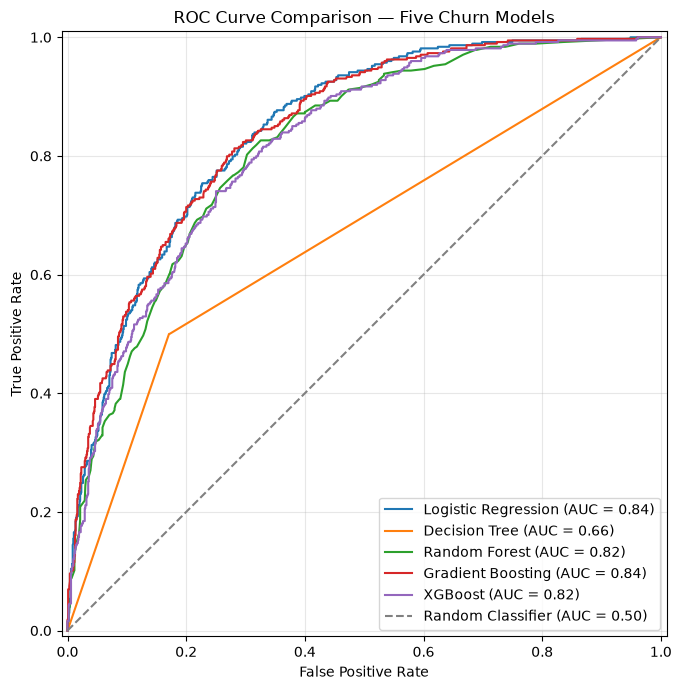

ROC curve chart saved to: D:\telco-customer-churn\Reports\roc_curve_comparison.png


In [26]:

# ROC curves for all five models

import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import RocCurveDisplay

# Creating the figure
fig, ax = plt.subplots(figsize=(10, 7))

# Fitting each pipeline on training data and plot its ROC curve
for model_name, pipeline in model_pipelines.items():

    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_train, y_train)

    RocCurveDisplay.from_estimator(
        fitted_pipeline,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

# Adding the random-classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random Classifier (AUC = 0.50)"
)

ax.set_title("ROC Curve Comparison — Five Churn Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Saving the chart
output_path = Path("../Reports/roc_curve_comparison.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve chart saved to:", output_path.resolve())


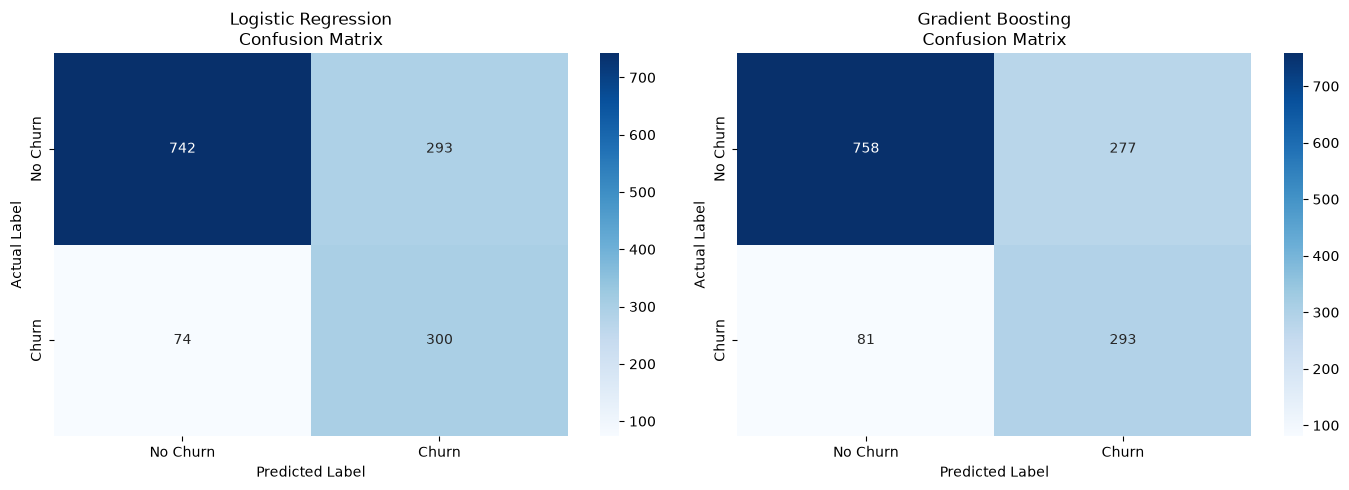

In [27]:

# Confusion matrices for the top two models

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

top_models = ["Logistic Regression", "Gradient Boosting"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model_name in zip(axes, top_models):
    y_pred = model_pipelines[model_name].predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{model_name}\nConfusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()

# Save the figure for reports and presentation
plt.savefig(
    "../Reports/top_2_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

# Hyperparameter tuning: Logistic Regression

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform

# Use the existing complete pipeline
lr_pipeline = model_pipelines["Logistic Regression"]

# Define the cross-validation strategy
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search across different regularization strengths
param_distributions = {
    "model__C": loguniform(1e-3, 1e2)
}

# Configure randomized search
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit using training data only
lr_search.fit(X_train, y_train)

print("Best parameters:", lr_search.best_params_)
print("Best cross-validation ROC-AUC:", round(lr_search.best_score_, 4))


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'model__C': np.float64(0.0745934328572655)}
Best cross-validation ROC-AUC: 0.8477


In [29]:
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score
)

# Best estimator has already been refitted on X_train
best_lr = lr_search.best_estimator_

# Evaluate on the untouched test set
y_test_pred = best_lr.predict(X_test)
y_test_proba = best_lr.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression — Test Results")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")

Tuned Logistic Regression — Test Results
---------------------------------------------
Accuracy:  0.7410
Precision: 0.5077
Recall:    0.7941
F1-score:  0.6194
ROC-AUC:   0.8453


In [30]:

# Hyperparameter tuning: Gradient Boosting

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

# Getting the existing complete pipeline
gb_pipeline = model_pipelines["Gradient Boosting"]

# Using the same 5-fold cross-validation strategy
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Defining the hyperparameter search space
gb_param_distributions = {
    "model__n_estimators": randint(50, 251),
    "model__learning_rate": uniform(0.02, 0.18),
    "model__max_depth": randint(1, 4),
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__subsample": uniform(0.7, 0.3)
}

# Configuring randomized search
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fitting on training data only
gb_search.fit(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print(
    "Best cross-validation ROC-AUC:",
    round(gb_search.best_score_, 4)
)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'model__learning_rate': np.float64(0.13455387402748045), 'model__max_depth': 1, 'model__min_samples_leaf': 4, 'model__min_samples_split': 6, 'model__n_estimators': 200, 'model__subsample': np.float64(0.8813252137833452)}
Best cross-validation ROC-AUC: 0.8508


In [31]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Retrieve the best pipeline, refitted on all training data
best_gb = gb_search.best_estimator_

# Predict on the untouched test set
gb_test_pred = best_gb.predict(X_test)
gb_test_proba = best_gb.predict_proba(X_test)[:, 1]

print("Tuned Gradient Boosting — Test Results")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_test, gb_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, gb_test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, gb_test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, gb_test_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, gb_test_proba):.4f}")


Tuned Gradient Boosting — Test Results
---------------------------------------------
Accuracy:  0.8013
Precision: 0.6577
Recall:    0.5241
F1-score:  0.5833
ROC-AUC:   0.8483


In [32]:

import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Collect test-set metrics for both tuned models
tuned_comparison = pd.DataFrame([
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba)
    },
    {
        "Model": "Tuned Gradient Boosting",
        "Accuracy": accuracy_score(y_test, gb_test_pred),
        "Precision": precision_score(y_test, gb_test_pred, zero_division=0),
        "Recall": recall_score(y_test, gb_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, gb_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, gb_test_proba)
    }
])

# Sort by ROC-AUC, highest first
tuned_comparison = (
    tuned_comparison
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

# Save results to Reports
output_dir = Path("../Reports")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "tuned_model_comparison.csv"
excel_path = output_dir / "tuned_model_comparison.xlsx"

tuned_comparison.to_csv(csv_path, index=False)
tuned_comparison.to_excel(excel_path, index=False)

print("Tuned model comparison:")
display(tuned_comparison.round(4))

print("\nFiles saved successfully:")
print(csv_path.resolve())
print(excel_path.resolve())


Tuned model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Gradient Boosting,0.8013,0.6577,0.5241,0.5833,0.8483
1,Tuned Logistic Regression,0.7410,0.5077,0.7941,0.6194,0.8453



Files saved successfully:
D:\telco-customer-churn\Reports\tuned_model_comparison.csv
D:\telco-customer-churn\Reports\tuned_model_comparison.xlsx


In [35]:

import joblib
from pathlib import Path

# Create the Model folder path
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Get the best tuned Logistic Regression pipeline
final_model = lr_search.best_estimator_

# Save the complete pipeline
model_path = model_dir / "churn_model_v1.pkl"
joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())


Model saved successfully!
Saved location: D:\telco-customer-churn\models\churn_model_v1.pkl


In [36]:

# Load the saved model
loaded_model = joblib.load(model_path)

# Verify predictions on the existing test data
loaded_predictions = loaded_model.predict(X_test)

print("Model loaded successfully!")
print("Predictions generated:", len(loaded_predictions))
print("Predictions match original:",
      (loaded_predictions == y_test_pred).all())


Model loaded successfully!
Predictions generated: 1409
Predictions match original: True
